In [2]:
import pandas as pd

df = pd.read_csv("cancer_immunotherapy.csv")

In [4]:
# printing first 5 data

df.head()

,PatientID,Age,Gender,TumorType,ImmunotherapyType,BiomarkerExpressionLevel,TreatmentResponse,SurvivalInMonths,Relapse,MutationCount
0,P001,45,F,Lung,PD-1 Inhibitor,High,Partial Response,12,Yes,150
1,P002,67,M,Breast,CTLA-4 Inhibitor,Low,Stable Disease,20,No,320
2,P003,55,F,Melanoma,PD-L1 Inhibitor,Medium,Complete Response,36,No,50
3,P004,70,M,Lung,PD-1 Inhibitor,High,Progressive Disease,10,Yes,200
4,P005,38,F,Lung,CTLA-4 Inhibitor,Medium,Partial Response,24,No,80


In [7]:
# find the shape

df.shape

(10, 10)

In [9]:
# basix statictics

df.describe()

,Age,SurvivalInMonths,MutationCount
count,10.000000,10.000000,10.000000
mean,56.400000,21.800000,215.000000
std,12.231108,12.839176,107.935166
min,38.000000,8.000000,50.000000
25%,46.250000,12.500000,157.500000
50%,57.500000,18.000000,210.000000
75%,66.500000,28.500000,287.500000
max,72.000000,48.000000,400.000000


In [11]:
# find the columns

df.columns

Index(['PatientID', 'Age', 'Gender', 'TumorType', 'ImmunotherapyType',
       'BiomarkerExpressionLevel', 'TreatmentResponse', 'SurvivalInMonths',
       'Relapse', 'MutationCount'],
      dtype='object')

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   PatientID                 10 non-null     object
 1   Age                       10 non-null     int64 
 2   Gender                    10 non-null     object
 3   TumorType                 10 non-null     object
 4   ImmunotherapyType         10 non-null     object
 5   BiomarkerExpressionLevel  10 non-null     object
 6   TreatmentResponse         10 non-null     object
 7   SurvivalInMonths          10 non-null     int64 
 8   Relapse                   10 non-null     object
 9   MutationCount             10 non-null     int64 
dtypes: int64(3), object(7)
memory usage: 928.0+ bytes


In [14]:
# find the no of patients in the dataset

len(df)

10

In [15]:
# how many patients have each tumor type

df["TumorType"].value_counts()

Lung        4
Breast      3
Melanoma    3
Name: TumorType, dtype: int64

In [16]:
# find the average survival for each tumor type

df.groupby("TumorType")["SurvivalInMonths"].mean()

TumorType
Breast      14.666667
Lung        15.000000
Melanoma    38.000000
Name: SurvivalInMonths, dtype: float64

In [17]:
# find the average mutation count for each tumor type

df.groupby("TumorType")["MutationCount"].mean()

TumorType
Breast      340.0
Lung        170.0
Melanoma    150.0
Name: MutationCount, dtype: float64

In [18]:
# count patients receiving each immuno theraphy

df["ImmunotherapyType"].value_counts()

PD-1 Inhibitor      4
CTLA-4 Inhibitor    3
PD-L1 Inhibitor     3
Name: ImmunotherapyType, dtype: int64

In [19]:
# compare survival between immuno theraphy types

df.groupby("ImmunotherapyType")["SurvivalInMonths"].mean()

ImmunotherapyType
CTLA-4 Inhibitor    30.666667
PD-1 Inhibitor      11.500000
PD-L1 Inhibitor     26.666667
Name: SurvivalInMonths, dtype: float64

In [20]:
# compare treatment response by immunotheraphy

pd.crosstab(
    df["ImmunotherapyType"],
    df["TreatmentResponse"]
)

TreatmentResponse,Complete Response,Partial Response,Progressive Disease,Stable Disease
ImmunotherapyType,,,,
CTLA-4 Inhibitor,1,1,0,1
PD-1 Inhibitor,0,2,2,0
PD-L1 Inhibitor,1,0,0,2


In [21]:
# count patients by biomaker expression

df["BiomarkerExpressionLevel"].value_counts()

High      4
Low       3
Medium    3
Name: BiomarkerExpressionLevel, dtype: int64

In [22]:
# compare survival according to biomaker level

df.groupby("BiomarkerExpressionLevel")["SurvivalInMonths"].mean()

BiomarkerExpressionLevel
High      16.500000
Low       14.666667
Medium    36.000000
Name: SurvivalInMonths, dtype: float64

In [25]:
# compare biomaker response with treatment response

pd.crosstab(
    df["BiomarkerExpressionLevel"],
    df["TreatmentResponse"]
)

TreatmentResponse,Complete Response,Partial Response,Progressive Disease,Stable Disease
BiomarkerExpressionLevel,,,,
High,0,1,1,2
Low,0,1,1,1
Medium,2,1,0,0


In [27]:
# wowwwwwwwwwwwwwwwwwwwwwwww here is the point of creating charts

import matplotlib.pyplot as plt
import seaborn as sns

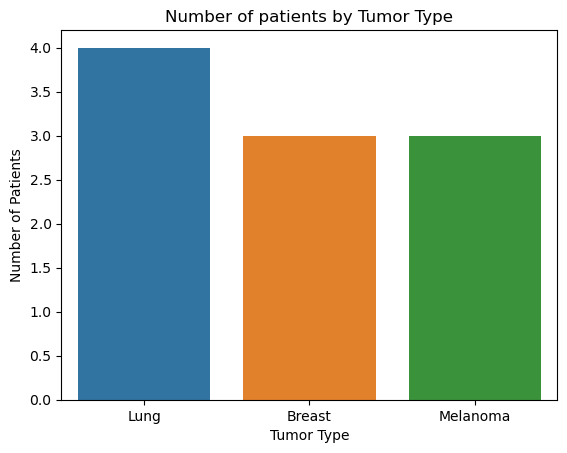

In [28]:
# How many patients belong to each cancer type? - bar chart
sns.countplot(data = df, x = "TumorType")
plt.title("Number of patients by Tumor Type")
plt.xlabel("Tumor Type")
plt.ylabel("Number of Patients")
plt.show()

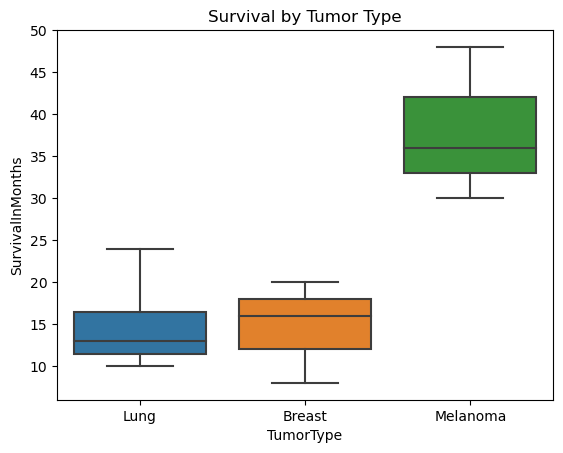

In [29]:
# Box plot - Survival by Tumor Type
sns.boxplot(
    data = df,
    x = "TumorType",
    y = "SurvivalInMonths"
)

plt.title("Survival by Tumor Type")
plt.show()

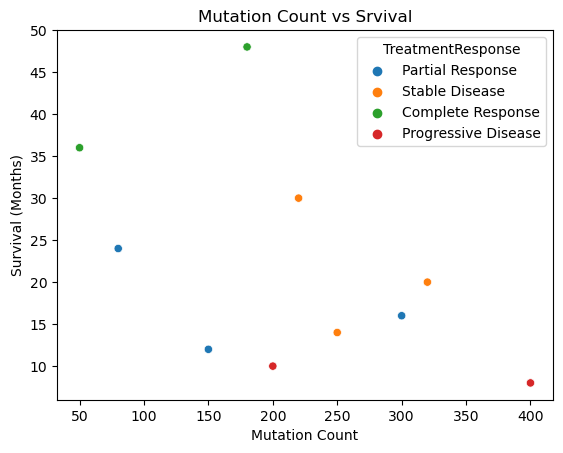

In [30]:
# Scatter plot - Mutation Count vs Srvival
sns.scatterplot(
    data = df,
    x = "MutationCount",
    y = "SurvivalInMonths",
    hue = "TreatmentResponse"
)

plt.title("Mutation Count vs Srvival")
plt.xlabel("Mutation Count")
plt.ylabel("Survival (Months)")
plt.show()

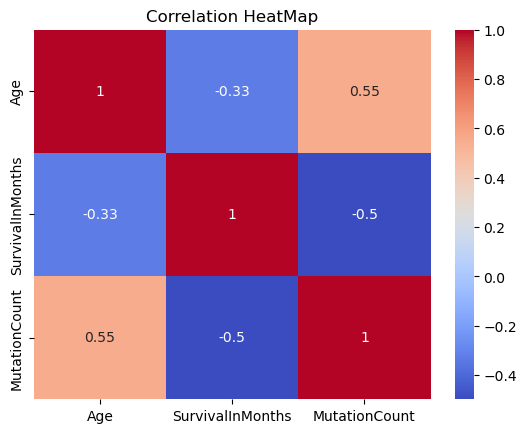

In [36]:
# Heatmap

numeric_df = df[
    ["Age", "SurvivalInMonths", "MutationCount"]
]
correlation = numeric_df.corr()
sns.heatmap(
    correlation,
    annot = True,
    cmap = "coolwarm"
)

plt.title("Correlation HeatMap")
plt.show()

In [37]:
# Creating a DNA sequence

dna = "CTTTCTGTCCCGCCCTTCCTCTGA"

print(dna)

CTTTCTGTCCCGCCCTTCCTCTGA


In [38]:
# Sequence type

type(dna)

str

In [40]:
# Sequence length

len(dna)

24

In [41]:
# Counting Nucleotides

print("Number of Adenine: ", dna.count("A"))
print("Number of T: ", dna.count("T"))
print("Number of Cytosine: ", dna.count("C"))
print("Number of G: ", dna.count("G"))

Number of Adenine:  1
Number of T:  9
Number of Cytosine:  11
Number of G:  3


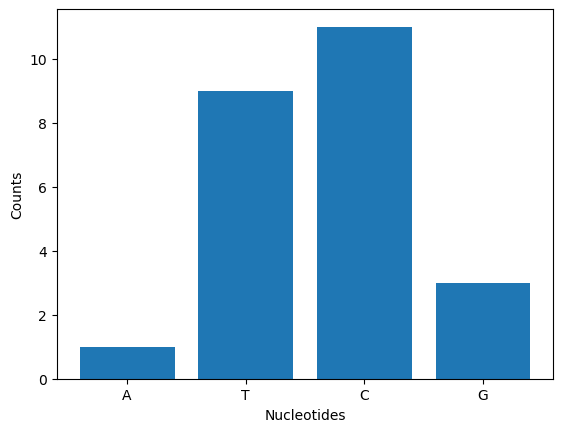

In [42]:
A = dna.count("A")
T = dna.count("T")
C = dna.count("C")
G = dna.count("G")

nucleotides = ["A", "T", "C", "G"]
counts = [A, T, C, G]
plt.bar(nucleotides, counts)
plt.xlabel("Nucleotides")
plt.ylabel("Counts")
plt.show()

In [43]:
# GC_Content
# GC_Content = ((G+C)/Total_Nucleotide)x100

gc_count = dna.count("G") + dna.count("C")
gc_content = (gc_count / len(dna) * 100)
print("GC_Content: ", gc_content, "%")

GC_Content:  58.333333333333336 %


In [44]:
# DNA -> RNA

rna = dna.replace("T", "U")
print("DNA", dna)
print("RNA", rna)

DNA CTTTCTGTCCCGCCCTTCCTCTGA
RNA CUUUCUGUCCCGCCCUUCCUCUGA


In [45]:
# translate = applies that mapping to the entire sequence

complement = dna.translate(str.maketrans("ATGC", "TACG"))
print(complement)

GAAAGACAGGGCGGGAAGGAGACT


In [46]:
# reverse complement

reverse_complement = complement[::-1]
# Take the sequnce from begining to end with a step 0f -1

print(reverse_complement)

TCAGAGGAAGGGCGGGACAGAAAG
